In [1]:
import utils_runup
import requests
import pandas as pd
from datetime import datetime

hourly = pd.date_range(start='2024-11-01', end='2024-11-01', freq='D')
formatted_time = hourly.strftime("%Y-%m-%d")


timestamps = formatted_time
twl_region = 1
siteid = 1548
lat, lon = 41.897136303912966, -69.96233057531904
savefolder = "test"

In [4]:
# Get tide from TWL forecast

import os

print('getting tide')

records = []


for timestamp in timestamps:
    d = utils_runup.fetch_water_level_data(timestamp = timestamp,
        region_choice = twl_region, site_id = siteid,
        lat = lat, lon = lon,
        distance_m=500, save_folder= "data_wl")
            
    data_timestamps = pd.to_datetime(d['dateTime'], utc=True)

    TWL_forecast =  d.items()
    target_timestamp = pd.to_datetime(timestamp, utc=True)   
    closest_index = abs(data_timestamps - target_timestamp).argmin()
    
    TWL_forecast = {key: values[closest_index] for key, values in d.items()}
    tide = TWL_forecast['tideWindSetup']
    


    url = "https://vdatum.noaa.gov/vdatumweb/api/convert"


    params = {
        "wlon": lon,
        "wlat": lat,
        "region": "CONTIGUOUS",
        "s_h_frame": "NAD83_2011",
        "s_h_zone": "19",
        "s_coor": "utm",
        "s_h_unit": "m",
        "s_v_frame": "LMSL",
        "s_v_unit": "m",
        "s_v_elevation": "height",
        "s_v_geoid": "geoid18",
        "s_z": "0.0",
        "t_h_frame": "NAD83_2011",
        "t_coor": "utm",
        "t_h_unit": "m",
        "t_h_zone": "19",
        "t_v_frame": "NAVD88",
        "t_v_unit": "m",
        "t_v_elevation": "height",
        "t_v_geoid": "geoid18",
        "epoch_in": "0.0",
        "epoch_out": "0.0"
                }


    response = requests.get(url, params=params)
    vdatum_data = response.json()
    print(vdatum_data)
    t_z = float(vdatum_data.get("t_z"))
    tide = tide + t_z
    TWL_forecast['twl'] += t_z
    TWL_forecast['twl05'] += t_z
    TWL_forecast['twl95'] += t_z
    TWL_forecast['tideWindSetup'] += t_z

    records.append(TWL_forecast)

df = pd.DataFrame(records)
print(df.head())

getting tide
Boston, MA
{'region': 'CONTIGUOUS', 's_h_frame': 'NAD83_2011', 's_coor': 'utm', 's_h_unit': 'm', 's_h_zone': '19', 's_v_frame': 'LMSL', 's_v_unit': 'm', 's_v_elevation': 'height', 's_v_geoid': 'geoid18', 's_x': '-75.0', 's_y': '36.0', 's_z': '0.0', 't_h_frame': 'NAD83_2011', 't_coor': 'utm', 't_h_unit': 'm', 't_h_zone': '', 't_v_frame': 'NAVD88', 't_v_unit': 'm', 't_v_elevation': 'height', 't_v_geoid': 'geoid18', 'epoch_in': '0.0', 'epoch_out': '0.0', 't_x': '-75', 't_y': '36', 't_z': '-999999', 'uncertainty': ''}
             id   dateTime        twl     twl05      twl95  setup  runup  \
0  2.962579e+09 2024-11-01 -999999.26 -999999.4 -999999.12   0.17   0.47   

   runup05  runup95  tideWindSetup  swash  incSwash  infragSwash    hs  \
0     0.33     0.61     -999999.56    0.5      0.37         0.34  0.65   

       pp predictedImpact  predictedImpactCode  
0  5.5509            None                  0.0  


In [6]:
d = utils_runup.fetch_water_level_data(timestamp = "2024-11-13",
        region_choice = 1, site_id = 1548,
        lat = lat, lon = lon,
        distance_m=500, save_folder= "data_wl")

Boston, MA
getting water level forecast
Water level data saved to data_wl\Boston,_MA_1548_2024-11-13.json


{'id': [2974342717.0, 2974342718.0, 2974342719.0, 2974342720.0, 2974342721.0, 2974342722.0, 2974342723.0, 2974342724.0, 2974342725.0, 2974342726.0, 2974342727.0, 2974342728.0, 2974342729.0, 2974342730.0, 2974342731.0, 2974342732.0, 2974342733.0, 2974342734.0, 2974342735.0, 2974342736.0, 2974342737.0, 2974342738.0, 2974342739.0, 2974342740.0, 2974342741.0, 2974342742.0, 2974342743.0, 2974342744.0, 2974342745.0, 2974342746.0, 2974342747.0, 2974342748.0, 2974342749.0, 2974342750.0, 2974342751.0, 2974342752.0, 2974342753.0, 2974342754.0, 2974342755.0, 2974342756.0, 2974342757.0, 2974342758.0, 2974342759.0, 2974342760.0, 2974342761.0, 2974342762.0, 2974342763.0, 2974342764.0, 2974342765.0, 2974342766.0, 2974342767.0, 2974342768.0, 2974342769.0, 2974342770.0, 2974342771.0, 2974342772.0, 2974342773.0, 2974342774.0, 2974342775.0, 2974342776.0, 2974342777.0, 2974342778.0, 2974342779.0, 2974342780.0, 2974342781.0, 2974342782.0, 2974342783.0, 2974342784.0, 2974342785.0, 2974342786.0, 2974342787.0

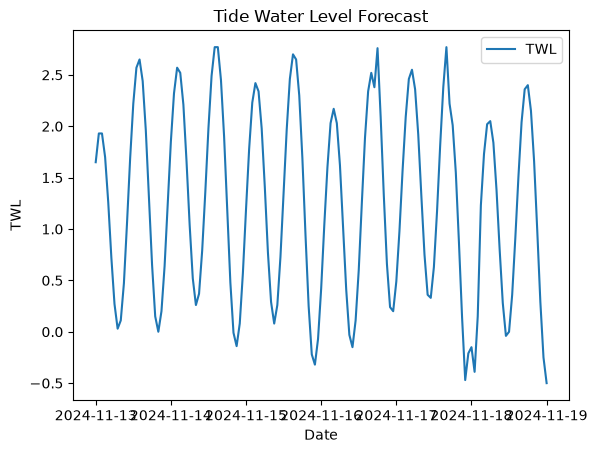

In [7]:
import matplotlib.pyplot as plt

print(d)
plt.plot(d['dateTime'], d['twl'], label='TWL')
plt.xlabel('Date')
plt.ylabel('TWL')
plt.title('Tide Water Level Forecast')
plt.legend()
plt.show()
